# Winning Model Clarification
## WQI Prediction Pipeline — Jalaur River System

---

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import seaborn as sns
import os

BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), '..'))
OUT_DIR  = os.path.join(BASE_DIR, 'outputs', 'internal_evaluation')
print('Base:', BASE_DIR)
print('Eval:', OUT_DIR)

Base: d:\CaelianProj\water_analysis
Eval: d:\CaelianProj\water_analysis\outputs\internal_evaluation


## 2. Official Model Comparison (Final_Documentation.pdf, Section 4)

In [ ]:
official = pd.DataFrame({
    'Algorithm':  ['MLP (Neural Net)', 'XGBoost', 'Random Forest', 'SVM'],
    'Accuracy_%': [99.25, 98.50, 98.50, 93.98],
    'F1_Score_%': [99.20, 98.57, 98.07, 94.35],
    'Rank':       [1, 2, 3, 4],
    'Notes': [
        'WINNER - Perfect minority class recall. Final deployed model.',
        'Very strong, handled complex relationships well.',
        'Fast, struggled slightly with rarest class.',
        'Failed to identify minority classes on test set.',
    ]
})

def highlight_winner(row):
    s = 'background-color:#1a472a;color:white;font-weight:bold' if row['Rank']==1 else ''
    return [s] * len(row)

official.style \
    .apply(highlight_winner, axis=1) \
    .format({'Accuracy_%': '{:.2f}%', 'F1_Score_%': '{:.2f}%'}) \
    .set_caption('Table 1: Official Model Comparison (Final_Documentation.pdf)') \
    .hide(axis='index')

Algorithm,Accuracy_%,F1_Score_%,Rank,Notes
MLP (Neural Net),99.25%,99.20%,1,WINNER - Perfect minority class recall. Final deployed model.
XGBoost,98.50%,98.57%,2,"Very strong, handled complex relationships well."
Random Forest,98.50%,98.07%,3,"Fast, struggled slightly with rarest class."
SVM,93.98%,94.35%,4,Failed to identify minority classes on test set.


## 3. Visual Bar Chart — Accuracy & F1 by Model

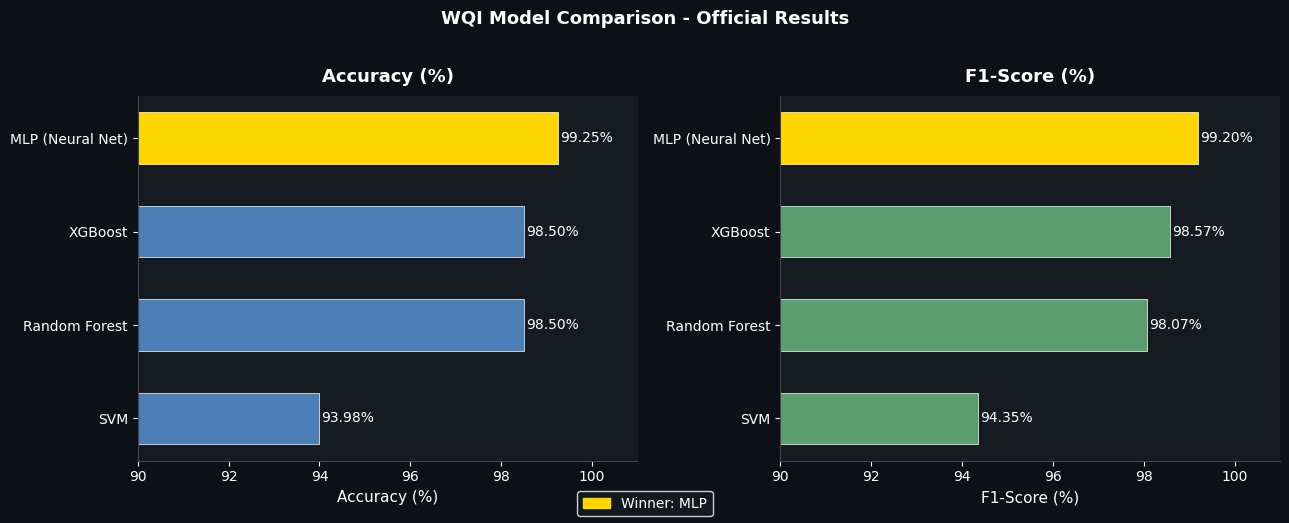

Saved: outputs/model_comparison_official.png


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.patch.set_facecolor('#0d1117')

models   = official['Algorithm'].tolist()
accuracy = official['Accuracy_%'].tolist()
f1       = official['F1_Score_%'].tolist()
colors_acc = ['#FFD700' if m == 'MLP (Neural Net)' else '#4a7eb5' for m in models]
colors_f1  = ['#FFD700' if m == 'MLP (Neural Net)' else '#5a9e6e' for m in models]

for ax, values, colors, lbl in [
    (axes[0], accuracy, colors_acc, 'Accuracy (%)'),
    (axes[1], f1,       colors_f1,  'F1-Score (%)'),
]:
    ax.set_facecolor('#161b22')
    bars = ax.barh(models[::-1], values[::-1], color=colors[::-1],
                   edgecolor='white', linewidth=0.5, height=0.55)
    ax.set_xlabel(lbl, color='white', fontsize=11)
    ax.set_title(lbl, color='white', fontsize=13, fontweight='bold', pad=10)
    ax.tick_params(colors='white')
    for sp in ['top', 'right']:   ax.spines[sp].set_visible(False)
    for sp in ['bottom', 'left']: ax.spines[sp].set_color('#444')
    ax.set_xlim(90, 101)
    for bar, val in zip(bars, values[::-1]):
        ax.text(bar.get_width()+0.05, bar.get_y()+bar.get_height()/2,
                f'{val:.2f}%', va='center', ha='left', color='white', fontsize=10)

gold = mpatches.Patch(color='#FFD700', label='Winner: MLP')
fig.legend(handles=[gold], loc='lower center',
           facecolor='#161b22', edgecolor='white', labelcolor='white')
plt.suptitle('WQI Model Comparison - Official Results',
             color='white', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'outputs', 'model_comparison_official.png'),
            dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('Saved: outputs/model_comparison_official.png')

## 4. Early CSV vs. Official — The Source of Confusion

In [18]:
early = pd.read_csv(os.path.join(BASE_DIR, 'outputs', 'model_results.csv'))
early['Accuracy_%'] = (early['Accuracy']*100).round(2)
early['F1_Score_%'] = (early['F1_Score']*100).round(2)
early = early[['Model','Accuracy_%','F1_Score_%']].rename(columns={'Model':'Algorithm'})
early['Source'] = 'model_results.csv  (EARLY / untuned — ignore)'

final = official[['Algorithm','Accuracy_%','F1_Score_%']].copy()
final['Source'] = 'Final_Documentation.pdf  (OFFICIAL — use this)'

combined = pd.concat([early, final], ignore_index=True)

def color_source(row):
    if 'OFFICIAL' in row['Source']:
        return ['background-color:#1a472a;color:white'] * len(row)
    return ['background-color:#4a1942;color:#ccc'] * len(row)

combined.style \
    .apply(color_source, axis=1) \
    .format({'Accuracy_%':'{:.2f}%','F1_Score_%':'{:.2f}%'}) \
    .set_caption('Table 2: Early CSV vs Official — Source of Confusion') \
    .hide(axis='index')

Algorithm,Accuracy_%,F1_Score_%,Source
XGBoost,96.69%,96.59%,model_results.csv (EARLY / untuned — ignore)
MLP,90.73%,91.78%,model_results.csv (EARLY / untuned — ignore)
MLP (Neural Net),99.25%,99.20%,Final_Documentation.pdf (OFFICIAL — use this)
XGBoost,98.50%,98.57%,Final_Documentation.pdf (OFFICIAL — use this)
Random Forest,98.50%,98.07%,Final_Documentation.pdf (OFFICIAL — use this)
SVM,93.98%,94.35%,Final_Documentation.pdf (OFFICIAL — use this)


## 5. Deployed XGBoost — Internal Holdout Evaluation

> Generated by `python internal_evaluation.py`. The deployed backend model is still `xgboost_model.pkl` from the early run.

In [19]:
summary_full = pd.read_csv(os.path.join(OUT_DIR, 'summary_full.csv'))
per_class    = pd.read_csv(os.path.join(OUT_DIR, 'per_class_full.csv'))

print('=' * 55)
print('DEPLOYED XGBOOST - FULL HOLDOUT SET (n=151)')
print('=' * 55)
for _, row in summary_full.iterrows():
    if row['Metric'] in ('Records', 'Classes present'):
        v = int(float(row['Value']))
    else:
        v = f"{float(row['Value']):.4f}"
    print(f"  {row['Metric']:<35s}: {v}")
print()
print('PER-CLASS RESULTS:')
print(per_class.round(4).to_string(index=False))

DEPLOYED XGBOOST - FULL HOLDOUT SET (n=151)
  Records                            : 151
  Classes present                    : 5
  Accuracy                           : 0.9669
  Weighted F1                        : 0.9659
  Macro F1 (classes present)         : 0.7906

PER-CLASS RESULTS:
    Class  Precision  Recall     F1  Support
Excellent     1.0000  1.0000 1.0000        6
     Good     1.0000  0.8333 0.9091        6
     Fair     0.5556  1.0000 0.7143        5
     Poor     0.5000  0.2500 0.3333        4
High Risk     1.0000  0.9923 0.9961      130


## 6. Confusion Matrix — Deployed XGBoost on 20% Holdout

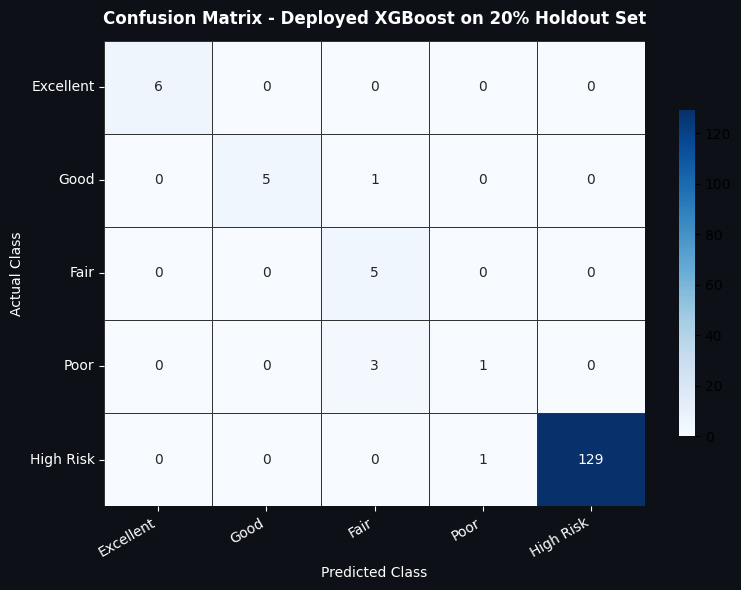

Saved: outputs/confusion_matrix_deployed.png


In [20]:
cm_df   = pd.read_csv(os.path.join(OUT_DIR, 'confusion_matrix_full.csv'), index_col=0)
classes = [c.replace('Actual ', '') for c in cm_df.index.tolist()]

fig, ax = plt.subplots(figsize=(8, 6))
fig.patch.set_facecolor('#0d1117')
ax.set_facecolor('#161b22')

sns.heatmap(cm_df.values.astype(int), annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes,
            linewidths=0.5, linecolor='#333', ax=ax, cbar_kws={'shrink':0.7})

ax.set_title('Confusion Matrix - Deployed XGBoost on 20% Holdout Set',
             color='white', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Predicted Class', color='white')
ax.set_ylabel('Actual Class',    color='white')
ax.tick_params(colors='white')
plt.setp(ax.get_xticklabels(), rotation=30, ha='right', color='white')
plt.setp(ax.get_yticklabels(), rotation=0, color='white')
plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'outputs', 'confusion_matrix_deployed.png'),
            dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('Saved: outputs/confusion_matrix_deployed.png')

## 7. Class Distribution — Why SMOTE Was Essential

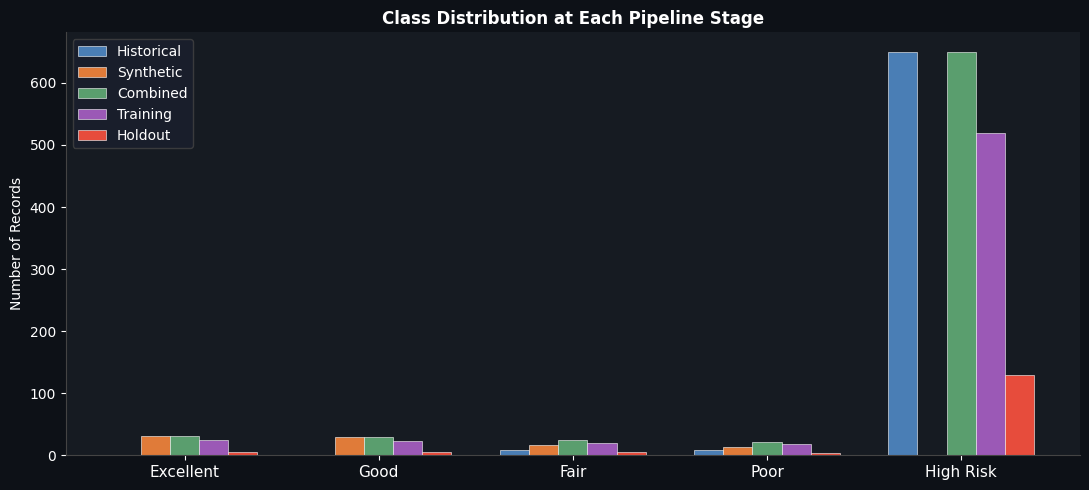

In [21]:
dist = pd.read_csv(os.path.join(OUT_DIR, 'class_distribution.csv'), index_col=0).drop('Total', errors='ignore')

fig, ax = plt.subplots(figsize=(11, 5))
fig.patch.set_facecolor('#0d1117')
ax.set_facecolor('#161b22')

cols    = [c for c in ['Historical','Synthetic','Combined','Training','Holdout'] if c in dist.columns]
x       = np.arange(len(dist.index))
w       = 0.15
palette = ['#4a7eb5','#e07b39','#5a9e6e','#9b59b6','#e74c3c']

for i, (col, color) in enumerate(zip(cols, palette)):
    ax.bar(x + i*w, dist[col], w, label=col, color=color, edgecolor='white', linewidth=0.4)

ax.set_xticks(x + w*(len(cols)-1)/2)
ax.set_xticklabels(dist.index, color='white', fontsize=11)
ax.set_ylabel('Number of Records', color='white')
ax.set_title('Class Distribution at Each Pipeline Stage',
             color='white', fontsize=12, fontweight='bold')
ax.tick_params(colors='white')
for sp in ['top','right']:   ax.spines[sp].set_visible(False)
for sp in ['bottom','left']: ax.spines[sp].set_color('#444')
ax.legend(facecolor='#1a1f2e', edgecolor='#444', labelcolor='white', fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'outputs', 'class_distribution.png'),
            dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()

## Conclusion

| Question | Answer |
|---|---|
| **Winning model?** | **MLP (Neural Net)** — 99.25% accuracy, 99.20% F1 |

> *"The MLP (Neural Network) algorithm will be utilized for the final deployment. It achieved a near-perfect accuracy of 99.25% and was the only algorithm capable of perfectly identifying the Poor and Very Poor minority classes in the holdout test set without overfitting."*

---
*Notebook generated to clarify model selection for the WQI Prediction Pipeline study.*